# Phase 20 — Feature Selection & Model Refinement

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Use the expanded Phase 19 features to assess redundancy and select a compact predictor set using training data only, then compare candidate models on the existing validation period. The test set is not used for feature selection or model choice.

**Important:** This notebook relies on Phase 19's expanded feature table and Phase 13's fixed chronological split files. It preserves the target endpoint metadata and checks split boundaries. It does not claim that feature importance proves causality or profitability.

## 1. Setup and locate Phase 19 / Phase 13 outputs

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

EXPANDED_REL = Path("data/processed/expanded_features/asx_3m_expanded_features_targets.csv")
TRAIN_REL = Path("data/processed/model_features/asx_3m_strict_split_train.csv")
VALID_REL = Path("data/processed/model_features/asx_3m_strict_split_validation.csv")
TEST_REL = Path("data/processed/model_features/asx_3m_strict_split_test.csv")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if all((p / r).exists() for r in [EXPANDED_REL, TRAIN_REL, VALID_REL, TEST_REL]):
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and all((p / r).exists() for r in [EXPANDED_REL, TRAIN_REL, VALID_REL, TEST_REL]):
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find Phase 19 expanded table and Phase 13 splits. Run those phases first.")

OUT = PROJECT_ROOT / "reports" / "feature_selection_refinement"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: e:\Projects\Australian Stock Market Data Science Project


## 2. Load expanded features and define the fixed train/validation periods

In [2]:
expanded = pd.read_csv(PROJECT_ROOT / EXPANDED_REL, low_memory=False)
expanded.columns = [str(c).strip().lower() for c in expanded.columns]
for c in ["date", "target_endpoint_date_3m"]:
    if c in expanded.columns:
        expanded[c] = pd.to_datetime(expanded[c], errors="coerce")
expanded["ticker"] = expanded["ticker"].astype(str).str.strip().str.upper()
expanded["forward_return_3m"] = pd.to_numeric(expanded["forward_return_3m"], errors="coerce")

def read_split_dates(path):
    part = pd.read_csv(path, low_memory=False)
    part.columns = [str(c).strip().lower() for c in part.columns]
    part["date"] = pd.to_datetime(part["date"], errors="coerce")
    part["target_endpoint_date_3m"] = pd.to_datetime(part["target_endpoint_date_3m"], errors="coerce")
    return part

train0 = read_split_dates(PROJECT_ROOT / TRAIN_REL)
valid0 = read_split_dates(PROJECT_ROOT / VALID_REL)
test0 = read_split_dates(PROJECT_ROOT / TEST_REL)

train_start, train_end = train0["date"].min(), train0["date"].max()
valid_start, valid_end = valid0["date"].min(), valid0["date"].max()
test_start = test0["date"].min()

train = expanded[
    (expanded["date"] >= train_start) &
    (expanded["date"] <= train_end) &
    (expanded["target_endpoint_date_3m"] < valid_start)
].copy()
valid = expanded[
    (expanded["date"] >= valid_start) &
    (expanded["date"] <= valid_end) &
    (expanded["target_endpoint_date_3m"] < test_start)
].copy()

if train.empty or valid.empty:
    raise ValueError("Expanded train or validation split is empty. Check date alignment.")

assert train["target_endpoint_date_3m"].max() < valid_start
assert valid["target_endpoint_date_3m"].max() < test_start
print("Train rows:", len(train), "| Validation rows:", len(valid))
print("Train endpoint max:", train["target_endpoint_date_3m"].max())
print("Validation endpoint max:", valid["target_endpoint_date_3m"].max())

Train rows: 40447 | Validation rows: 6084
Train endpoint max: 2025-02-17 00:00:00
Validation endpoint max: 2025-10-31 00:00:00


## 3. Identify candidate features and exclude metadata

In [3]:
metadata_cols = {
    "ticker", "date", "target_endpoint_date_3m", "target_endpoint_price_3m",
    "close_for_target", "target_horizon_observations", "forward_return_3m",
    "target_source_price_column", "target_definition"
}
candidate_features = [
    c for c in expanded.columns
    if c not in metadata_cols and pd.api.types.is_numeric_dtype(expanded[c])
]
# Exclude the raw close price used to construct the target if it appears in the table.
candidate_features = [c for c in candidate_features if c not in {"close_for_features"}]
print("Candidate feature count:", len(candidate_features))
print(candidate_features)

Candidate feature count: 29
['momentum_21d_x', 'momentum_63d_x', 'benchmark_return_1d_x', 'benchmark_volatility_21d_x', 'benchmark_volatility_63d_x', 'momentum_1d', 'momentum_5d', 'momentum_21d_y', 'momentum_63d_y', 'momentum_126d', 'volatility_5d', 'volatility_21d', 'volatility_63d', 'price_to_sma_21d', 'price_to_sma_63d', 'price_to_sma_126d', 'short_term_reversal_1d', 'benchmark_return_1d_y', 'benchmark_return_5d', 'benchmark_return_21d', 'benchmark_return_63d', 'benchmark_return_126d', 'benchmark_volatility_5d', 'benchmark_volatility_21d_y', 'benchmark_volatility_63d_y', 'relative_momentum_5d', 'relative_momentum_21d', 'relative_momentum_63d', 'relative_momentum_126d']


## 4. Training-only missingness and redundancy analysis

In [4]:
# Calculate missingness and low-variance statistics using training data only.
quality_rows = []
for col in candidate_features:
    vals = pd.to_numeric(train[col], errors="coerce")
    quality_rows.append({
        "feature": col,
        "train_missing_rate": float(vals.isna().mean()),
        "train_unique_values": int(vals.nunique(dropna=True)),
        "train_std": float(vals.std()) if vals.notna().any() else np.nan
    })
quality = pd.DataFrame(quality_rows).sort_values(
    ["train_missing_rate", "train_std"], ascending=[True, False]
).reset_index(drop=True)
display(quality)
quality.to_csv(OUT / "training_feature_quality.csv", index=False)

# Remove all-missing and constant predictors based only on training data.
usable = quality.loc[
    (quality["train_missing_rate"] < 1.0) &
    (quality["train_unique_values"] > 1),
    "feature"
].tolist()
if not usable:
    raise ValueError("No usable numeric predictors remain.")

corr = train[usable].corr(numeric_only=True).abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
redundant = []
for col in upper.columns:
    high_corr_with = upper.index[upper[col] > 0.95].tolist()
    for other in high_corr_with:
        redundant.append({
            "feature_a": other, "feature_b": col,
            "absolute_correlation": float(corr.loc[other, col])
        })
redundancy = pd.DataFrame(redundant, columns=["feature_a", "feature_b", "absolute_correlation"])
display(redundancy.head(30))
quality.to_csv(OUT / "training_feature_quality.csv", index=False)
redundancy.to_csv(OUT / "high_correlation_feature_pairs.csv", index=False)

,feature,train_missing_rate,train_unique_values,train_std
0,benchmark_return_1d_x,0.001261,777,0.008162
1,benchmark_return_1d_y,0.001261,777,0.008162
2,momentum_1d,0.001286,35579,0.022977
3,short_term_reversal_1d,0.002571,35536,0.022985
4,benchmark_return_5d,0.006305,773,0.018306
5,benchmark_volatility_5d,0.006305,773,0.003525
6,momentum_5d,0.006428,37163,0.048540
7,relative_momentum_5d,0.006428,39489,0.045437
8,volatility_5d,0.006428,39434,0.014422
9,price_to_sma_21d,0.025713,39239,0.054253


,feature_a,feature_b,absolute_correlation
0,benchmark_return_1d_x,benchmark_return_1d_y,1.000000
1,benchmark_volatility_21d_y,benchmark_volatility_21d_x,0.976899
2,momentum_63d_y,relative_momentum_63d,0.963106
3,benchmark_volatility_63d_y,benchmark_volatility_63d_x,0.994658
4,momentum_63d_y,momentum_63d_x,0.981207
5,momentum_126d,relative_momentum_126d,0.973687


## 5. Select a compact feature set using training data only

For highly correlated pairs, retain the feature with lower missingness in the training set. This is a simple redundancy filter, not a claim that the retained feature is causally more important.

In [5]:
selected = list(usable)
missing_map = quality.set_index("feature")["train_missing_rate"].to_dict()
for _, row in redundancy.sort_values("absolute_correlation", ascending=False).iterrows():
    a, b = row["feature_a"], row["feature_b"]
    if a in selected and b in selected:
        # Drop the feature with higher training missingness; break ties deterministically.
        if missing_map.get(a, 1.0) > missing_map.get(b, 1.0):
            selected.remove(a)
        elif missing_map.get(b, 1.0) > missing_map.get(a, 1.0):
            selected.remove(b)
        else:
            selected.remove(max(a, b))

print("Selected feature count:", len(selected))
print("Selected features:", selected)
pd.DataFrame({"selected_feature": selected}).to_csv(OUT / "selected_feature_list.csv", index=False)

Selected feature count: 23
Selected features: ['benchmark_return_1d_x', 'momentum_1d', 'short_term_reversal_1d', 'benchmark_return_5d', 'benchmark_volatility_5d', 'momentum_5d', 'relative_momentum_5d', 'volatility_5d', 'price_to_sma_21d', 'benchmark_return_21d', 'benchmark_volatility_21d_y', 'momentum_21d_y', 'relative_momentum_21d', 'volatility_21d', 'momentum_21d_x', 'price_to_sma_63d', 'benchmark_return_63d', 'benchmark_volatility_63d_y', 'momentum_63d_y', 'volatility_63d', 'price_to_sma_126d', 'benchmark_return_126d', 'momentum_126d']


## 6. Compare baseline, Ridge, and Random Forest on validation

Preprocessing is fit within each pipeline using training rows only. Model choice is based on validation MAE. The test set is not evaluated in this phase.

,model,features,n_validation,MAE,RMSE,R2,predicted_mean
0,Training mean baseline,23,6084,0.141984,0.195113,-0.081749,0.021461
1,Selected-feature Ridge,23,6084,0.148157,0.205256,-0.197150,0.015029
2,Selected-feature Random Forest,23,6084,0.148196,0.205459,-0.199521,0.033152


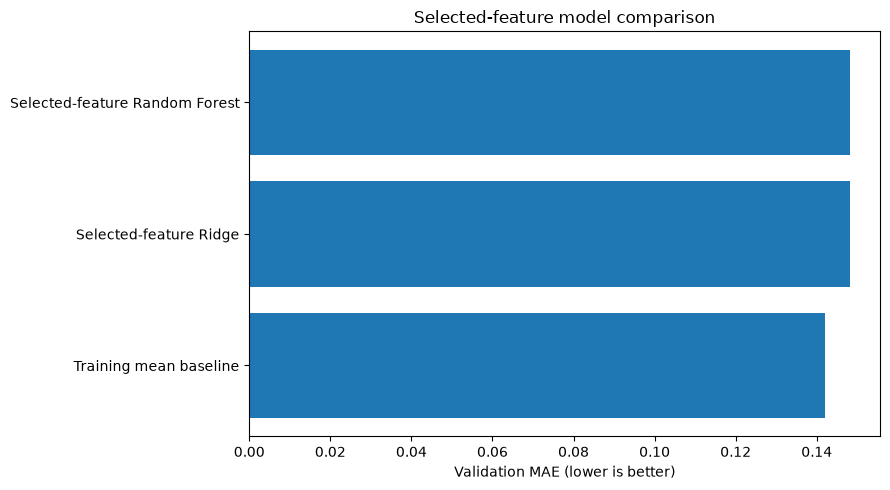

In [6]:
X_train = train[selected].replace([np.inf, -np.inf], np.nan)
y_train = train["forward_return_3m"].astype(float)
X_valid = valid[selected].replace([np.inf, -np.inf], np.nan)
y_valid = valid["forward_return_3m"].astype(float)

models = {
    "Training mean baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Selected-feature Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Selected-feature Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=250, min_samples_leaf=25, max_features=0.8,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

rows = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    p = model.predict(X_valid)
    rows.append({
        "model": name,
        "features": len(selected),
        "n_validation": len(y_valid),
        "MAE": mean_absolute_error(y_valid, p),
        "RMSE": np.sqrt(mean_squared_error(y_valid, p)),
        "R2": r2_score(y_valid, p),
        "predicted_mean": float(np.mean(p))
    })
results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(results)
results.to_csv(OUT / "selected_feature_validation_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = results.sort_values("MAE")
ax.barh(plot_df["model"], plot_df["MAE"])
ax.set_xlabel("Validation MAE (lower is better)")
ax.set_title("Selected-feature model comparison")
plt.tight_layout()
plt.savefig(OUT / "selected_feature_validation_mae.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Extract Random Forest importance if available

Tree-based importance can be unstable with correlated features. It is descriptive, not causal. The analysis is performed only for the validation-selected experiment, and does not use test data.

In [7]:
rf_name = "Selected-feature Random Forest"
if rf_name in fitted:
    rf_pipeline = fitted[rf_name]
    rf = rf_pipeline.named_steps["model"]
    importance = pd.DataFrame({
        "feature": selected,
        "importance": rf.feature_importances_
    }).sort_values("importance", ascending=False)
    display(importance)
    importance.to_csv(OUT / "random_forest_feature_importance.csv", index=False)
else:
    importance = pd.DataFrame()
    print("Random Forest model was not fitted.")

,feature,importance
19,volatility_63d,0.192460
22,momentum_126d,0.136624
21,benchmark_return_126d,0.095029
17,benchmark_volatility_63d_y,0.082763
13,volatility_21d,0.080010
18,momentum_63d_y,0.079421
20,price_to_sma_126d,0.051253
16,benchmark_return_63d,0.045313
10,benchmark_volatility_21d_y,0.037469
15,price_to_sma_63d,0.033738


## 8. Save Phase 20 summary

In [8]:
best = results.iloc[0]
baseline = results[results["model"] == "Training mean baseline"].iloc[0]
summary = {
    "phase": 20,
    "candidate_feature_count": int(len(candidate_features)),
    "usable_feature_count": int(len(usable)),
    "selected_feature_count": int(len(selected)),
    "selected_features": selected,
    "train_rows": int(len(train)),
    "validation_rows": int(len(valid)),
    "best_validation_model": str(best["model"]),
    "best_validation_mae": float(best["MAE"]),
    "baseline_validation_mae": float(baseline["MAE"]),
    "best_beats_baseline": bool(best["MAE"] < baseline["MAE"]),
    "test_rows_scored": 0,
    "warning": "Training-only feature screening with validation comparison. Correlation and importance are not causal evidence; test data remains untouched."
}
with open(OUT / "phase20_feature_selection_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print("\nOutputs saved to:", OUT)

{
  "phase": 20,
  "candidate_feature_count": 29,
  "usable_feature_count": 29,
  "selected_feature_count": 23,
  "selected_features": [
    "benchmark_return_1d_x",
    "momentum_1d",
    "short_term_reversal_1d",
    "benchmark_return_5d",
    "benchmark_volatility_5d",
    "momentum_5d",
    "relative_momentum_5d",
    "volatility_5d",
    "price_to_sma_21d",
    "benchmark_return_21d",
    "benchmark_volatility_21d_y",
    "momentum_21d_y",
    "relative_momentum_21d",
    "volatility_21d",
    "momentum_21d_x",
    "price_to_sma_63d",
    "benchmark_return_63d",
    "benchmark_volatility_63d_y",
    "momentum_63d_y",
    "volatility_63d",
    "price_to_sma_126d",
    "benchmark_return_126d",
    "momentum_126d"
  ],
  "train_rows": 40447,
  "validation_rows": 6084,
  "best_validation_model": "Training mean baseline",
  "best_validation_mae": 0.14198443955103976,
  "baseline_validation_mae": 0.14198443955103976,
  "best_beats_baseline": false,
  "test_rows_scored": 0,
  "warning": 

## 9. Completion checklist

- Confirm train/validation endpoint checks passed.
- Review the selected feature list and highly correlated pairs.
- Compare validation MAE with the mean baseline.
- Do not use test metrics to alter feature selection.
- If no model beats the baseline, report that honestly and consider a different research target rather than adding complexity blindly.